# Task 5: Model Evaluation and Kaggle Submission

## 5.1 Validation Set Evaluation

In [1]:
import torch
import torch.nn as nn
from pathlib import Path
from torchvision.models import resnet18
from data_pipeline import create_dataloaders

PROJECT_DIR = Path.cwd()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load the same validation dataset used during training
data = create_dataloaders(data_dir=PROJECT_DIR)

val_loader = data.val_loader
class_to_idx = data.class_to_idx
idx_to_class = data.idx_to_class

# Load the best fine-tuned checkpoint
checkpoint = torch.load(
    PROJECT_DIR / "best_resnet18_finetuned.pth",
    map_location=device,
    weights_only=True
)

model = resnet18(weights=None)
model.fc = nn.Linear(model.fc.in_features, 8)

model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)
model.eval()

assert checkpoint["class_to_idx"] == class_to_idx

print("Device:", device)
print("Validation images:", len(val_loader.dataset))
print("Best fine-tuning epoch:", checkpoint["epoch"])
print(f"Saved validation accuracy: {checkpoint['val_accuracy'] * 100:.2f}%")

Device: cpu
Validation images: 12729
Best fine-tuning epoch: 4
Saved validation accuracy: 98.76%


## 5.2 Evaluate the validation dataset

In [2]:
import torch
import torch.nn as nn

criterion = nn.CrossEntropyLoss()

true_labels = []
predicted_labels = []

total_loss = 0
correct = 0
total = 0

model.eval()

with torch.no_grad():
    for batch_index, (images, labels) in enumerate(val_loader):
        images = images.to(device)
        labels = labels.to(device)

        # Generate predictions
        outputs = model(images)
        loss = criterion(outputs, labels)

        predictions = outputs.argmax(dim=1)

        # Calculate loss and accuracy
        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        correct += (predictions == labels).sum().item()
        total += batch_size

        # Store labels for additional evaluation metrics
        true_labels.extend(labels.cpu().tolist())
        predicted_labels.extend(predictions.cpu().tolist())

        if (batch_index + 1) % 100 == 0:
            print(f"Processed {batch_index + 1}/{len(val_loader)} batches")

validation_accuracy = correct / total
validation_loss = total_loss / total

print(f"\nValidation Accuracy: {validation_accuracy * 100:.2f}%")
print(f"Validation Loss: {validation_loss:.4f}")
print(f"Total Images Evaluated: {total}")

KeyboardInterrupt: 

## 5.3 Find Precision, Recall and F1-Score

In [3]:
from sklearn.metrics import classification_report

class_names = [idx_to_class[i] for i in range(8)]

print(classification_report(
    true_labels,
    predicted_labels,
    labels=range(8),
    target_names=class_names,
    digits=4
))

              precision    recall  f1-score   support

      CatEye     0.9874    0.9903    0.9888      2775
     CatFace     0.9978    0.9986    0.9982      1389
    CatMouth     0.9957    0.9950    0.9953      1388
     CatNose     0.9883    0.9733    0.9808      1388
      DogEye     0.9675    0.9888    0.9780      2315
     DogFace     0.9974    0.9896    0.9935      1158
    DogMouth     0.9940    0.9957    0.9948      1158
     DogNose     0.9902    0.9637    0.9768      1158

    accuracy                         0.9876     12729
   macro avg     0.9898    0.9869    0.9883     12729
weighted avg     0.9877    0.9876    0.9876     12729



## 5.4 Create Confusion Matrix

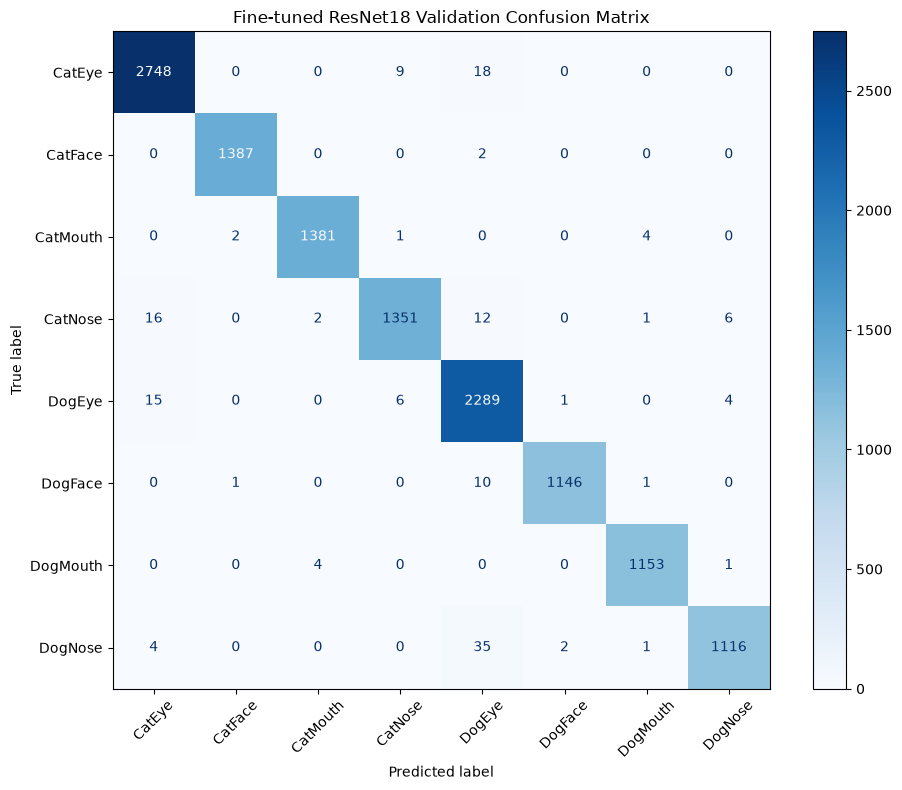

In [4]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    true_labels,
    predicted_labels,
    labels=range(8)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(10, 8))

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d"
)

plt.title("Fine-tuned ResNet18 Validation Confusion Matrix")
plt.tight_layout()
plt.show()